In [5]:
from pathlib import Path

In [7]:
%pip install pandas

  Using cached pandas-3.1.0-cp313-cp313-macosx_11_0_arm64.whl.metadata (18 kB)
Using cached pandas-3.1.0-cp313-cp313-macosx_11_0_arm64.whl (11.2 MB)

[notice] A new release of pip is available: 26.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


#Loading the data and checking the datatypes

In [15]:
import pandas as pd

In [20]:
data_dir = Path(
    "/Users/sahil/CircuitCost/CircuitCost/ML4Accel-Dataset/"
    "fpga_ml_dataset/HLS_dataset/polybench/"
    "gemm/xczu9eg-ffvb1156-2-i"
)

hls = pd.read_csv(data_dir / "post_hls_info.csv")
impl = pd.read_csv(data_dir / "post_implementation_info.csv")

In [21]:
hls.head()

,prj,clk_target(ns),clk_estimated(ns),clk_uncertainty(ns),bram,dsp,ff,lut,c_num_arith,c_num_logic,rtl_num_arith,rtl_num_logic,data_input_port(numxbits),data_output_port(numxbits)
0,io1_l2n1n1_l4n1n1,10.0,8.419,1.25,32,5,758,1239,22,9,19,9,5x32,1x32
1,io1_l2n1n1_l4n1p1,10.0,8.419,1.25,32,5,933,1356,23,9,20,9,5x32,1x32
2,io1_l2n1n1_l4p1n1,10.0,9.298,1.25,32,5,4578,3914,146,71,17,71,5x32,1x32
3,io1_l2n1p1_l4n1n1,10.0,8.419,1.25,32,5,845,1416,24,12,21,12,5x32,1x32
4,io1_l2n1p1_l4n1p1,10.0,8.419,1.25,32,5,1020,1519,25,12,22,12,5x32,1x32


In [22]:
impl.head()

,prj,vivado_dynamic_pwr(mW),Total LUTs,Logic LUTs,LUTRAMs,SRLs,FFs,RAMB36,RAMB18,DSP48 Blocks,freq(MHz)
0,io1_l2n1n1_l4n1n1,13.326,645,645,0,0,586,16,0,5,100
1,io1_l2n1n1_l4n1p1,13.207,656,647,0,9,529,16,0,5,100
2,io1_l2n1n1_l4p1n1,24.084,4131,4131,0,0,4202,16,0,5,100
3,io1_l2n1p1_l4n1n1,16.977,813,813,0,0,682,16,0,5,100
4,io1_l2n1p1_l4n1p1,17.611,833,824,0,9,626,16,0,5,100


In [23]:
print("HLS rows and columns:", hls.shape)

HLS rows and columns: (531, 14)


In [24]:
print("Implementation rows and columns", impl.shape)

Implementation rows and columns (531, 11)


In [33]:
print("HLS columns:")
#print(*hls.columns, sep="\n")
print(hls.dtypes)


HLS columns:
prj                               str
clk_target(ns)                float64
clk_estimated(ns)             float64
clk_uncertainty(ns)           float64
bram                            int64
dsp                             int64
ff                              int64
lut                             int64
c_num_arith                     int64
c_num_logic                     int64
rtl_num_arith                   int64
rtl_num_logic                   int64
data_input_port(numxbits)         str
data_output_port(numxbits)        str
dtype: object


In [34]:
print("Implementation columns:")
#print(*impl.columns, sep="\n")
print(impl.dtypes)

Implementation columns:
prj                           str
vivado_dynamic_pwr(mW)    float64
Total LUTs                  int64
Logic LUTs                  int64
LUTRAMs                     int64
SRLs                        int64
FFs                         int64
RAMB36                      int64
RAMB18                      int64
DSP48 Blocks                int64
freq(MHz)                   int64
dtype: object


#Checking wether data is complete or not

In [ ]:
#Checking missing values
print(hls.isna().sum())
#No missing values found

prj                           0
clk_target(ns)                0
clk_estimated(ns)             0
clk_uncertainty(ns)           0
bram                          0
dsp                           0
ff                            0
lut                           0
c_num_arith                   0
c_num_logic                   0
rtl_num_arith                 0
rtl_num_logic                 0
data_input_port(numxbits)     0
data_output_port(numxbits)    0
dtype: int64


In [41]:
print(impl.isna().sum())
#No missing values found

prj                       0
vivado_dynamic_pwr(mW)    0
Total LUTs                0
Logic LUTs                0
LUTRAMs                   0
SRLs                      0
FFs                       0
RAMB36                    0
RAMB18                    0
DSP48 Blocks              0
freq(MHz)                 0
dtype: int64


In [42]:
display(hls.head(10))

,prj,clk_target(ns),clk_estimated(ns),clk_uncertainty(ns),bram,dsp,ff,lut,c_num_arith,c_num_logic,rtl_num_arith,rtl_num_logic,data_input_port(numxbits),data_output_port(numxbits)
0,io1_l2n1n1_l4n1n1,10.0,8.419,1.25,32,5,758,1239,22,9,19,9,5x32,1x32
1,io1_l2n1n1_l4n1p1,10.0,8.419,1.25,32,5,933,1356,23,9,20,9,5x32,1x32
2,io1_l2n1n1_l4p1n1,10.0,9.298,1.25,32,5,4578,3914,146,71,17,71,5x32,1x32
3,io1_l2n1p1_l4n1n1,10.0,8.419,1.25,32,5,845,1416,24,12,21,12,5x32,1x32
4,io1_l2n1p1_l4n1p1,10.0,8.419,1.25,32,5,1020,1519,25,12,22,12,5x32,1x32
5,io1_l2n1p1_l4p1n1,10.0,9.298,1.25,32,5,4633,4074,148,74,19,74,5x32,1x32
6,io1_l2p1n1_l4n1n1,10.0,8.835,1.25,32,16,8070,10665,230,134,42,134,5x32,1x32
7,io1_l2p1n1_l4n1p1,10.0,8.835,1.25,32,16,8277,10800,231,134,43,134,5x32,1x32
8,io1_l2p1n1_l4p1n1,10.0,8.999,1.25,32,16,11730,13326,354,196,40,196,5x32,1x32
9,io2_l2n1n1_l4n1n1,10.0,8.419,1.25,32,5,776,1508,22,9,19,9,8x32,2x32


In [45]:
display(impl.head(10))

,prj,vivado_dynamic_pwr(mW),Total LUTs,Logic LUTs,LUTRAMs,SRLs,FFs,RAMB36,RAMB18,DSP48 Blocks,freq(MHz)
0,io1_l2n1n1_l4n1n1,13.326,645,645,0,0,586,16,0,5,100
1,io1_l2n1n1_l4n1p1,13.207,656,647,0,9,529,16,0,5,100
2,io1_l2n1n1_l4p1n1,24.084,4131,4131,0,0,4202,16,0,5,100
3,io1_l2n1p1_l4n1n1,16.977,813,813,0,0,682,16,0,5,100
4,io1_l2n1p1_l4n1p1,17.611,833,824,0,9,626,16,0,5,100
5,io1_l2n1p1_l4p1n1,28.438,3994,3994,0,0,4252,16,0,5,100
6,io1_l2p1n1_l4n1n1,80.987,3752,3152,0,600,5907,16,0,16,100
7,io1_l2p1n1_l4n1p1,90.148,3771,3162,0,609,5944,16,0,16,100
8,io1_l2p1n1_l4p1n1,99.278,6887,6287,0,600,9968,16,0,16,100
9,io2_l2n1n1_l4n1n1,13.490,727,727,0,0,645,16,0,5,100


In [47]:
#Finding columns shared by both tables
common_columns = hls.columns.intersection(impl.columns)
display(common_columns)

Index(['prj'], dtype='str')

In [49]:
#Now Understand what the candidate represents
print(hls["prj"].head())
print(impl["prj"].head())

0    io1_l2n1n1_l4n1n1
1    io1_l2n1n1_l4n1p1
2    io1_l2n1n1_l4p1n1
3    io1_l2n1p1_l4n1n1
4    io1_l2n1p1_l4n1p1
Name: prj, dtype: str
0    io1_l2n1n1_l4n1n1
1    io1_l2n1n1_l4n1p1
2    io1_l2n1n1_l4p1n1
3    io1_l2n1p1_l4n1n1
4    io1_l2n1p1_l4n1p1
Name: prj, dtype: str


In [56]:
#Check completeness and Uniqueness
for name,table in [("HLS",hls),("Implementation",impl)]:
    print(name)
    print("Missing IDs:", table["prj"].isna().sum())
    print("Duplicate IDs:", table["prj"].duplicated().sum())

HLS
Missing IDs: 0
Duplicate IDs: 0
Implementation
Missing IDs: 0
Duplicate IDs: 0


In [59]:
#Check that Identifiers match across tables
hls_ids = set(hls["prj"])
impl_ids = set(impl["prj"])

print("Only in HLS", len(hls_ids - impl_ids))
print("Only in IMPL", len(impl_ids - hls_ids))

Only in HLS 0
Only in IMPL 0


In [61]:
#Join with checks enabled
combined = hls.merge(
    impl,
    on="prj",
    how="outer",
    validate="one_to_one",
    indicator=True,
)

print(combined["_merge"].value_counts())

_merge
both          531
left_only       0
right_only      0
Name: count, dtype: int64


In [64]:
#Dropping merge as it is not required anymore
combined = combined.drop(columns=["_merge"])

In [ ]:
#Calculating min, max and mean of lut and Total LUTs column from hls and impl table respectively
min_hls = min(hls["lut"])
print("Minimum lut count in HLS",min_hls)
max_hls = max(hls["lut"])
print("Maximum lut count in HLS",max_hls)
min_impl = min(impl["Total LUTs"])
print("Minimum lut count in impl",min_impl)
max_impl = max(impl["Total LUTs"])
print("Maximum lut count in impl",max_impl)
mean_hls_lut = (sum(hls["lut"])/len(hls["lut"]))
print("Mean of HLS estimated LUT", mean_hls_lut)
mean_impl_total_luts = (sum(impl["Total LUTs"])/len(impl["Total LUTs"]))
print("Mean of IMPL Total LUTs count",mean_impl_total_luts)

Minimum lut count in HLS 1239
Maximum lut count in HLS 89478
Minimum lut count in impl 645
Maximum lut count in impl 82245
Mean of HLS estimated LUT 15139.184557438795
Mean of IMPL Total LUTs count 10701.82109227872


In [79]:
#Calculating median and standard deviation
median_hls = hls["lut"].median()
median_impl = impl['Total LUTs'].median()

print("Median HLS LUTs",median_hls)
print("Median Impl LUTs", median_impl)

std_hls = hls["lut"].std()
std_impl = impl["Total LUTs"].std()

print("Standard Deviation HLS luts", std_hls)
print("Standard Deviation Impl luts", std_impl)

Median HLS LUTs 10185.0
Median Impl LUTs 5628.0
Standard Deviation HLS luts 16446.291921803986
Standard Deviation Impl luts 12969.143895023233


In [80]:
%pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 89.0 MB/s  0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 85.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 88.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matplotlib]

[notice] A new release of pip is available: 26.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [81]:
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


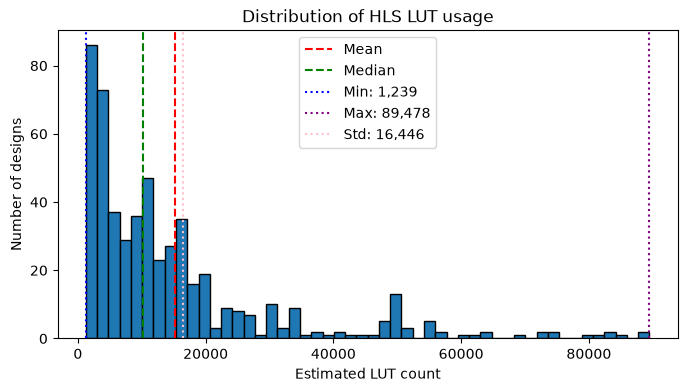

In [109]:
plt.figure(figsize=(8,4))

plt.hist(
    hls["lut"].dropna(),
    bins=50,
    edgecolor="black"
)

plt.xlabel("Estimated LUT count")
plt.ylabel("Number of designs")
plt.title("Distribution of HLS LUT usage")

#Marking mean and median
plt.axvline(
    hls["lut"].mean(),
    color="red",
    linestyle="--",
    label = "Mean"
)

plt.axvline(
    hls["lut"].median(),
    color="green",
    linestyle = "--",
    label = "Median"
)
#adding minimum and maximum
plt.axvline(
    hls["lut"].min(),
    color="blue",
    linestyle=":",
    label = f'Min: {hls["lut"].min():,.0f}'
)
plt.axvline(
    hls["lut"].max(),
    color="purple",
    linestyle=":",
    label = f'Max: {hls["lut"].max():,.0f}'
)

plt.axvline(
    hls["lut"].std(),
    color="pink",
    linestyle=":",
    label = f'Std: {hls["lut"].std():,.0f}'
)
plt.legend()
plt.show()

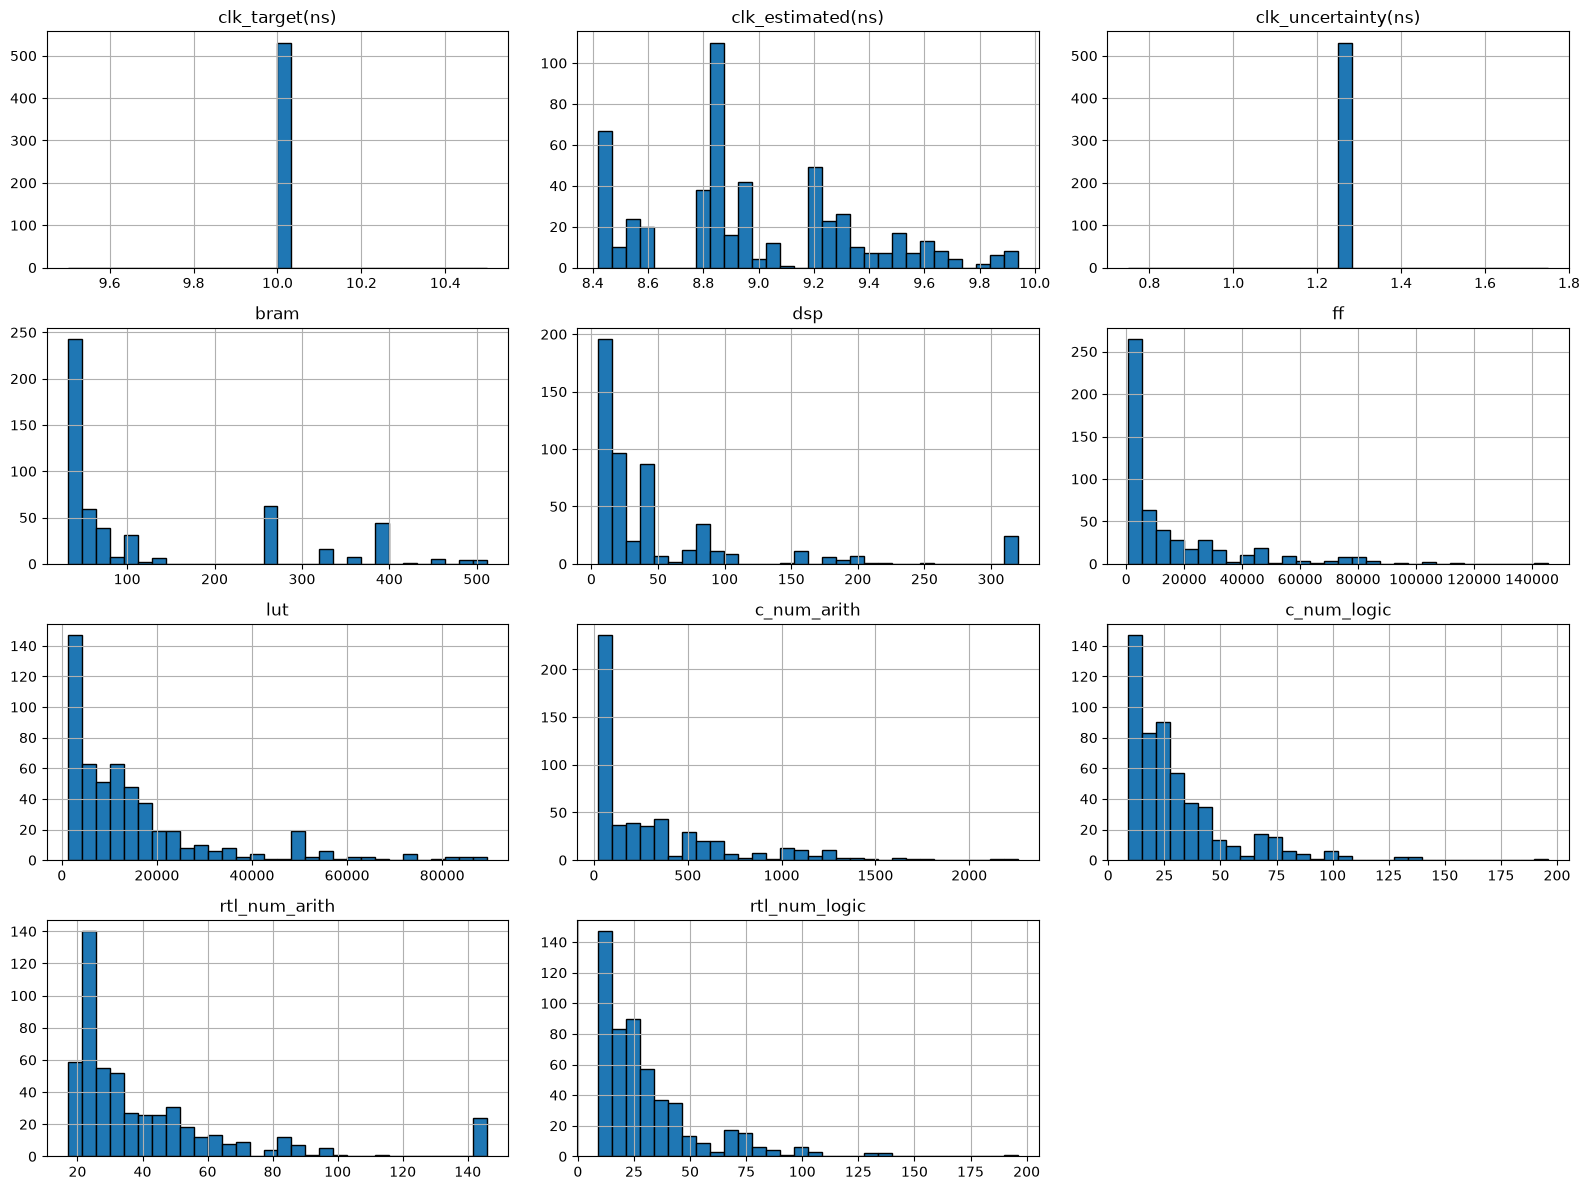

In [93]:
#plot every numerical column
hls.select_dtypes(include="number").hist(
    bins=30,
    figsize=(16, 12),
    edgecolor="black"
)

plt.tight_layout()
plt.show()

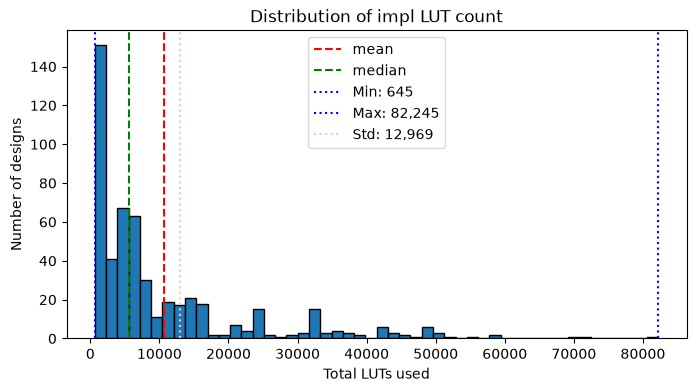

In [111]:
#Repeating smae for impl dataset

plt.figure(figsize=(8,4))

plt.hist(
    impl["Total LUTs"].dropna(),
    bins=50,
    edgecolor = "black"
)

plt.xlabel("Total LUTs used")
plt.ylabel("Number of designs")
plt.title("Distribution of impl LUT count")

plt.axvline(
    impl["Total LUTs"].mean(),
    color="red",
    linestyle="--",
    label="mean"
)

plt.axvline(
    impl["Total LUTs"].median(),
    color="green",
    linestyle = "--",
    label="median"
)

#Adding Minimum and Maximum

plt.axvline(
    impl["Total LUTs"].min(),
    color="blue",
    linestyle = ":",
    label=f'Min: {impl["Total LUTs"].min():,.0f}'
)

plt.axvline(
    impl["Total LUTs"].max(),
    color="blue",
    linestyle = ":",
    label=f'Max: {impl["Total LUTs"].max():,.0f}'
)

plt.axvline(
    impl["Total LUTs"].std(),
    color="pink",
    linestyle = ":",
    label=f'Std: {impl["Total LUTs"].std():,.0f}'
)

plt.legend()
plt.show()

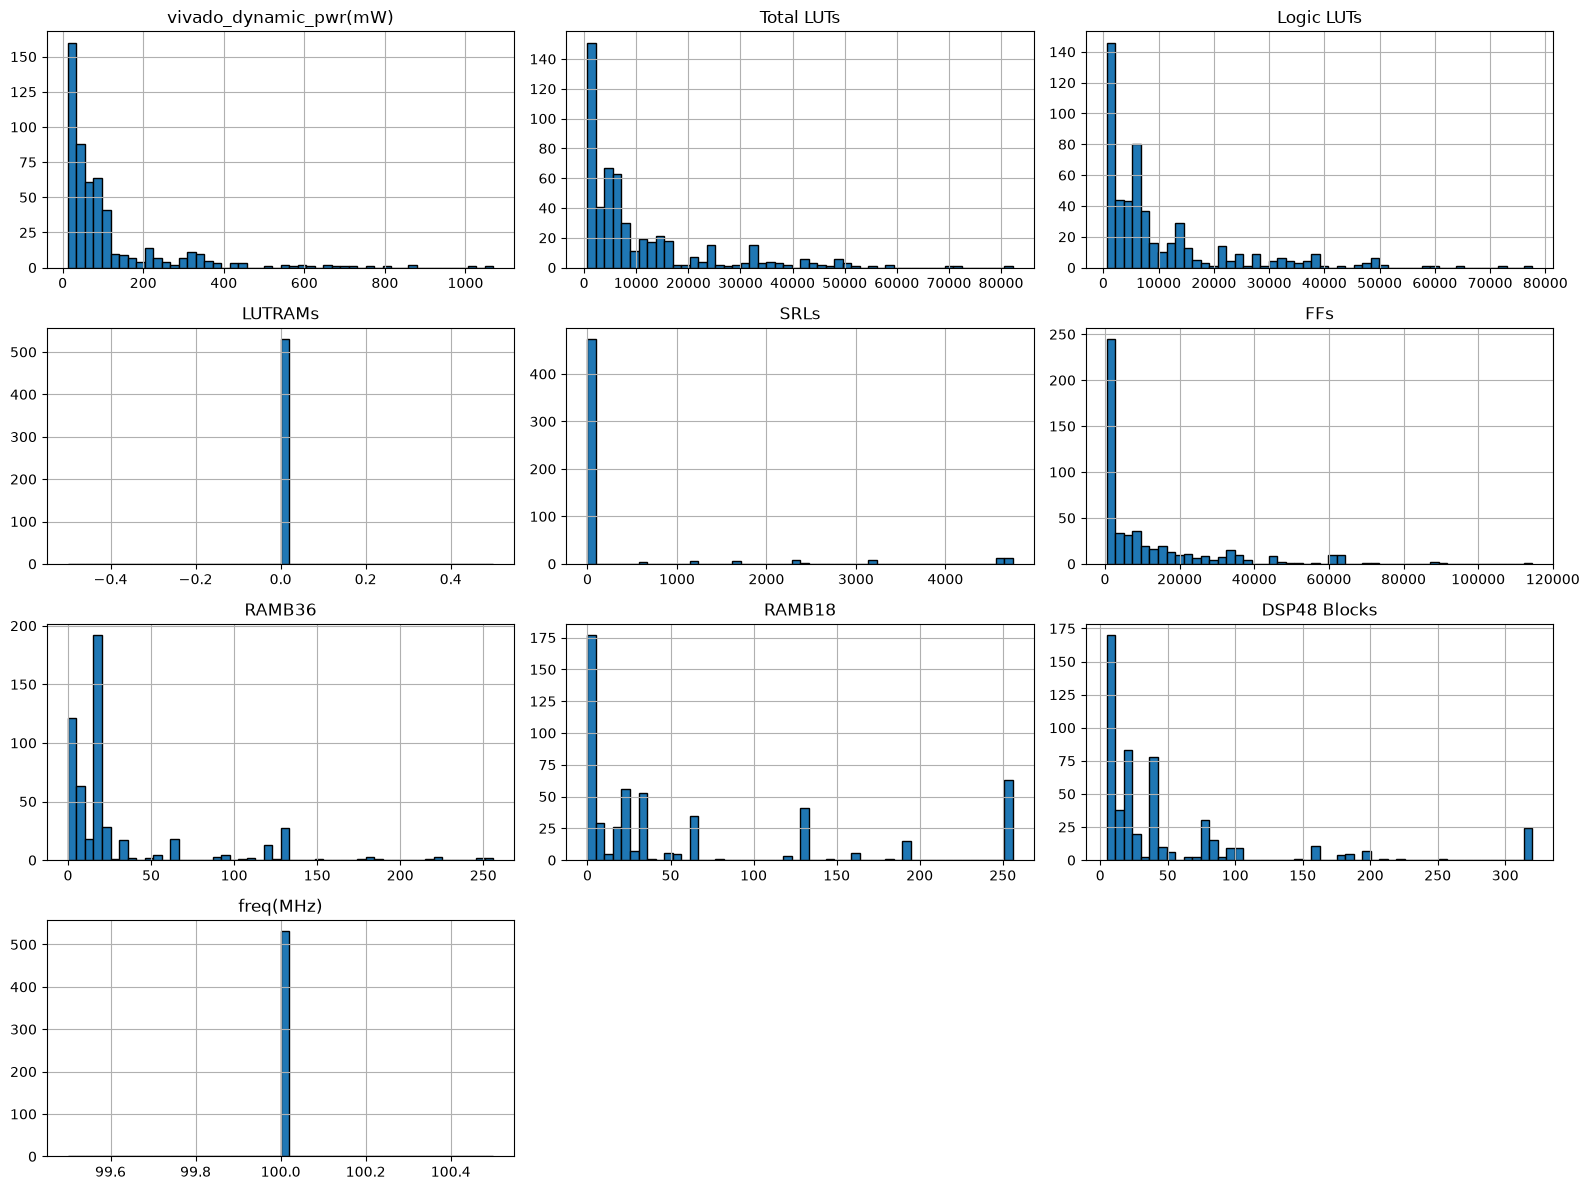

In [101]:
#Checking all other columns of impl dataset

impl.select_dtypes(include="number").hist(
    bins=50,
    figsize=(16,12),
    edgecolor="black"
)
plt.tight_layout()
plt.show()


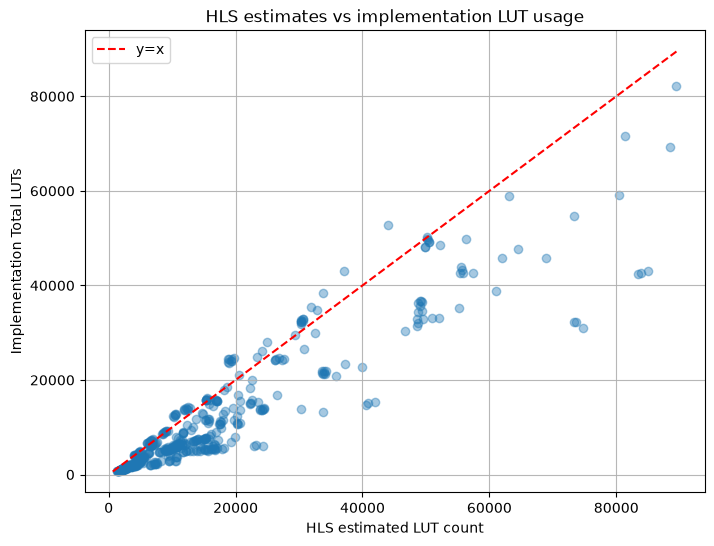

In [120]:
paired = hls[["prj","lut"]].merge(
    impl[["prj","Total LUTs"]],
    on="prj",
    how="inner",
    validate="one_to_one"
)

plt.figure(figsize=(8,6))

plt.scatter(
    paired["lut"],
    paired["Total LUTs"],
    alpha = 0.4
)

plt.xlabel("HLS estimated LUT count")
plt.ylabel("Implementation Total LUTs")
plt.title("HLS estimates vs implementation LUT usage")
plt.grid(alpha=0.9)

lower = min(paired["lut"].min(), paired["Total LUTs"].min())
upper = max(paired["lut"].max(), paired["Total LUTs"].max())

plt.plot(
    [lower,upper],
    [lower, upper],
    color="red",
    linestyle="--",
    label="y=x"
)
plt.legend()
plt.show()